# 02 — Linear Regression: Predicting the Recorded Activity Span (Supporting Exercise)

**Author:** Ali Čikić · General Assembly – Data Science Bootcamp

## 1. Goal

The goal is to build a simple **Linear Regression** model to see whether a few case-level variables are related to the
**recorded activity span** of a case (days from the first to the last recorded event, see `01_EDA.ipynb`).

- **Target:** `duration_days` (the recorded activity span)
- **Features:** `events_per_case`, `unique_activities`, `unique_resources`

This is a **supporting learning exercise**, not the early-warning model.

## 2. Load the Data

I load the same XES event log as in `01_EDA.ipynb` with PM4Py and convert it to a pandas DataFrame.

In [1]:
import os
import warnings
from pathlib import Path

os.environ["PM4PY_SHOW_PROGRESS_BAR"] = "false"  # no progress bar while loading
# hide only PM4Py's optional speed-up tip ("Install the optional requirement `r4pm` ..."); other warnings still show
warnings.filterwarnings("ignore", message="Install the optional requirement `r4pm`")

import matplotlib.pyplot as plt
import pandas as pd
import pm4py
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# the project folder: works whether Jupyter starts in the notebooks folder or in the project folder
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
data_path = project_root / "data" / "raw" / "BPIC15_1.xes"



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




*When PM4Py is imported it prints a short welcome and licence message. This is normal and not an error.*

In [2]:
log = pm4py.read_xes(str(data_path))
df = pm4py.convert_to_dataframe(log)

print("Events:", df.shape[0])
print("Cases:", df["case:concept:name"].nunique())
print("Columns:", df.shape[1])

Events: 52217
Cases: 1199
Columns: 29


## 3. Prepare Case-Level Data

The model needs **one row per case**, so I summarise the events of each case:

- `events_per_case` = total number of events in the case
- `unique_activities` = number of different activities
- `unique_resources` = number of different resources
- `duration_days` = recorded activity span in days (first to last event)

As in `01_EDA.ipynb`, I only use **completed cases**: cases with a recorded end date (`case:endDate` is not missing).

In [3]:
case_data = df.groupby("case:concept:name").agg(
    events_per_case=("concept:name", "size"),
    unique_activities=("concept:name", "nunique"),
    unique_resources=("org:resource", "nunique"),
    first_event=("time:timestamp", "min"),
    last_event=("time:timestamp", "max"),
    end_date=("case:endDate", "first"),
)
case_data["duration_days"] = (case_data["last_event"] - case_data["first_event"]).dt.total_seconds() / (24 * 60 * 60)

case_data = case_data[case_data["end_date"].notna()]   # completed cases only
case_data = case_data.reset_index().rename(columns={"case:concept:name": "case_id"})
case_data = case_data[["case_id", "events_per_case", "unique_activities", "unique_resources", "duration_days"]]

print("Completed cases:", len(case_data))
case_data.head()

Completed cases: 956


,case_id,events_per_case,unique_activities,unique_resources,duration_days
0,10009138,45,45,3,55.0
1,10051383,57,56,3,70.0
2,10053042,57,56,3,80.0
3,10093171,46,46,3,79.0
4,10186644,55,54,4,56.0


> **Supporting experiment.** These features describe the **whole finished case**, so they are only known after the
> case ends. This is a regression learning exercise, **not** an early-warning model.

## 4. Select Features and Target

- `X` contains the input features.
- `y` is the value we want to predict.

In [4]:
X = case_data[
    [
        "events_per_case",
        "unique_activities",
        "unique_resources"
    ]
]

y = case_data["duration_days"]

X.head()

,events_per_case,unique_activities,unique_resources
0,45,45,3
1,57,56,3
2,57,56,3
3,46,46,3
4,55,54,4


In [5]:
y.head()

0    55.0
1    70.0
2    80.0
3    79.0
4    56.0
Name: duration_days, dtype: float64

## 5. Train/Test Split

80% of the completed cases are used to train the model. 20% are used to test it on cases it has not seen before.

*This is a simple random split of the 956 completed cases. Notebooks 03–05 use exactly the same split; the early-warning
notebooks (07–12) use their own splits.*

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training cases:", len(X_train))
print("Test cases:", len(X_test))

Training cases: 764
Test cases: 192


## 6. Linear Regression Model

Linear Regression tries to find a linear relationship between the input features and the target:

$$
\text{duration\_days} = b_0 + b_1 \times \text{events\_per\_case} + b_2 \times \text{unique\_activities} + b_3 \times \text{unique\_resources}
$$

- $b_0$ = intercept
- $b_1, b_2, b_3$ = coefficients learned by the model

In [7]:
model = LinearRegression()

model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[ 10.01, -6.93,-13.39]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['events_per_case','unique_activities','unique_resources']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-15.37
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


### Model coefficients

In [8]:
coefficients = pd.DataFrame({
    "feature": X.columns,
    "coefficient": model.coef_
})

print("Intercept:", round(model.intercept_, 2))
coefficients

Intercept: -15.37


,feature,coefficient
0,events_per_case,10.014179
1,unique_activities,-6.930454
2,unique_resources,-13.386687


A **positive** coefficient means the predicted duration tends to increase when that feature increases, while the other
model features are held constant. A **negative** coefficient means the predicted duration tends to decrease.
This shows how the model uses the features; it does not mean that a feature *causes* longer or shorter cases.

## 7. Predictions

- **Actual** = real duration.
- **Predicted** = duration estimated by the model.

In [9]:
y_pred = model.predict(X_test)

predictions = pd.DataFrame({
    "actual": y_test.values,
    "predicted": y_pred
})
predictions.head()

,actual,predicted
0,49.301910,57.512595
1,44.644988,80.150458
2,56.958333,64.731831
3,55.000000,58.564380
4,98.540995,124.374399


## 8. Model Evaluation

- **MAE:** on average, how many days the predictions are away from the real values.
- **RMSE:** similar to MAE, but larger mistakes are penalised more.
- **R²:** shows how much of the variation in the recorded activity span is explained by the model (1 = perfect, 0 = no better than the average).

In [10]:
mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)

print(f"MAE: {mae:.2f} days")
print(f"RMSE: {rmse:.2f} days")
print(f"R²: {r2:.2f}")
print("Predictions below zero:", (y_pred < 0).sum(), f"| lowest prediction: {y_pred.min():.2f} days")

MAE: 59.01 days
RMSE: 126.02 days
R²: 0.26
Predictions below zero: 4 | lowest prediction: -14.39 days


### Simple baselines

The simplest possible "models" predict **one constant value** for every test case:

- **Mean baseline:** the average span of the training cases.
- **Median baseline:** the median span of the training cases.

**Why both?** MAE measures the average absolute error. On the training cases, the constant with the smallest MAE is the
**median**, not the mean. The spans have a long right tail, so a few very long cases pull the mean upwards. The median
baseline is therefore the harder and fairer constant to beat on MAE. The mean baseline is kept because R² compares a model
with predicting the mean.

In [11]:
mean_pred = [y_train.mean()] * len(y_test)
median_pred = [y_train.median()] * len(y_test)

print(f"Mean baseline (predicts {y_train.mean():.1f} days)   MAE: {mean_absolute_error(y_test, mean_pred):.2f} days")
print(f"Median baseline (predicts {y_train.median():.1f} days) MAE: {mean_absolute_error(y_test, median_pred):.2f} days")
print(f"Linear Regression                    MAE: {mae:.2f} days")

Mean baseline (predicts 96.3 days)   MAE: 71.98 days
Median baseline (predicts 63.0 days) MAE: 64.42 days
Linear Regression                    MAE: 59.01 days


## 9. Actual vs Predicted Plot

Points on the dashed line would be perfect predictions.

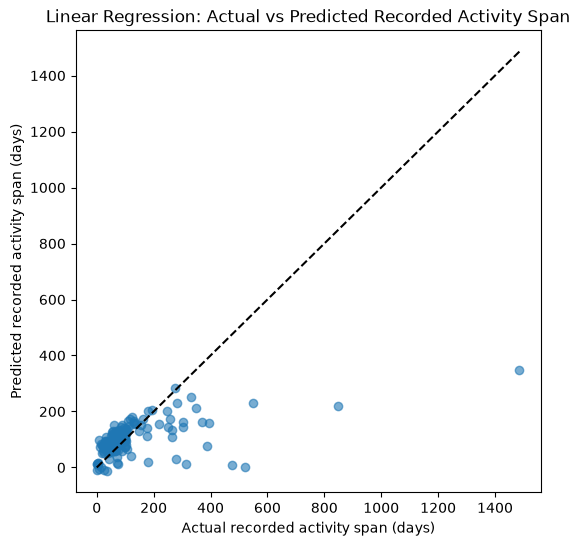

In [12]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([0, y_test.max()], [0, y_test.max()], linestyle="--", color="black")
plt.title("Linear Regression: Actual vs Predicted Recorded Activity Span")
plt.xlabel("Actual recorded activity span (days)")
plt.ylabel("Predicted recorded activity span (days)")
plt.show()

## 10. Simple Conclusion

1. **Did Linear Regression beat the baselines?** Yes. Its MAE (59.01 days) is lower than the mean baseline (71.98 days)
   and the median baseline (64.42 days). The gain over the median baseline, the fairer comparison for MAE, is about
   5 days per case.
2. **How strong is R²?** Weak. R² = 0.26, so the model explains only about a quarter of the variation in the recorded
   activity span. The RMSE (126.02 days) is much larger than the MAE, which shows that a few cases have very large errors.
3. **Which coefficients are positive or negative?** `events_per_case` is positive (about +10.0 days per extra event), while
   `unique_activities` (about −6.9) and `unique_resources` (about −13.4) are negative. `events_per_case` and
   `unique_activities` contain almost the same information (correlation 0.99 in `01_EDA.ipynb`), so their separate
   coefficients should not be interpreted one by one.
4. **Is Linear Regression good enough?** No. The plot shows that the model strongly underestimates the longest cases, and
   4 test predictions are below zero (the lowest is −14.39 days), which is impossible.

Linear Regression provides a simple first model, but it explains only part of the variation. These features are only known
once a case is finished, so this is a learning exercise and not an early-warning model.

**Next step:** compare Linear Regression with models that can capture non-linear relationships: Decision Tree, Random
Forest and Gradient Boosting (notebooks 03–05).